# Dataset – EuroSAT (Sentinel-2 satellite images, RGB)

**Source:** [EuroSAT RGB](https://zenodo.org/records/7711810) – Helber et al., *EuroSAT: A Novel Dataset and Deep
Learning Benchmark for Land Use and Land Cover Classification*, IEEE JSTARS 2019. 27,000 labelled 64×64 RGB
patches from the Sentinel-2 satellite in **10 land-use classes**.

**Why this dataset**
- Low-resolution image classification as the brief asks: every image is already **64×64**, the maximum allowed –
  it is what a satellite / drone camera on an edge device delivers, so no downscaling is needed.
- Not CIFAR-10; enough images (2,000–3,000 per class) for a CNN trained from scratch.
- Classes are nearly balanced (largest / smallest = 1.5).

**This notebook** downloads the data once, checks every image, makes a stratified **70 / 15 / 15** split
(seed 42) and writes it to `data/eurosat/train|val|test/<class>/`. The image folders are not committed (they
can be rebuilt in a minute); the split itself is committed in `data/eurosat_split.csv`, so every group member
gets exactly the same train / validation / test images.

In [1]:
import io
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

URL         = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip"
DATA_DIR    = Path("data")
ZIP_PATH    = DATA_DIR / "EuroSAT_RGB.zip"
OUT_DIR     = DATA_DIR / "eurosat"              # train/ val/ test/ <class>/ *.jpg  (not committed)
SPLIT_CSV   = DATA_DIR / "eurosat_split.csv"    # committed: which image is in which split
FIGURES_DIR = Path("figures")
IMG_SIZE    = (64, 64)
SEED        = 42

DATA_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

## 1. Download (once, ~95 MB)

In [2]:
if not ZIP_PATH.exists():
    print("Downloading", URL)
    urllib.request.urlretrieve(URL, ZIP_PATH)
print(f"{ZIP_PATH}: {ZIP_PATH.stat().st_size / 1e6:.1f} MB")

zf = zipfile.ZipFile(ZIP_PATH)
files = sorted(n for n in zf.namelist() if n.lower().endswith(".jpg"))
df = pd.DataFrame({"file": [Path(n).name for n in files],
                   "label": [Path(n).parent.name for n in files],
                   "zip_path": files})
CLASS_NAMES = sorted(df.label.unique())
print(f"{len(df)} images in {len(CLASS_NAMES)} classes")

data/EuroSAT_RGB.zip: 94.7 MB


27000 images in 10 classes


## 2. Check the images

In [3]:
# Every image must be a 64x64 RGB picture that opens without error
sizes, modes, broken = {}, {}, []
for p in df.zip_path:
    try:
        im = Image.open(io.BytesIO(zf.read(p)))
        im.load()
        sizes[im.size] = sizes.get(im.size, 0) + 1
        modes[im.mode] = modes.get(im.mode, 0) + 1
    except Exception:
        broken.append(p)
print("sizes :", sizes)
print("modes :", modes)
print("broken:", len(broken))
assert not broken and set(sizes) == {IMG_SIZE} and set(modes) == {"RGB"}

sizes : {(64, 64): 27000}
modes : {'RGB': 27000}
broken: 0


## 3. Stratified 70 / 15 / 15 split

In [4]:
if SPLIT_CSV.exists():
    # Re-use the committed split so every member has identical sets
    split = pd.read_csv(SPLIT_CSV)
    df = df.merge(split, on=["file", "label"], validate="one_to_one")
    print("Using the committed split from", SPLIT_CSV)
else:
    train_idx, temp_idx = train_test_split(df.index, test_size=0.30, stratify=df.label, random_state=SEED)
    val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=df.label[temp_idx], random_state=SEED)
    df["split"] = ""
    df.loc[train_idx, "split"], df.loc[val_idx, "split"], df.loc[test_idx, "split"] = "train", "val", "test"
    df[["file", "label", "split"]].sort_values(["split", "label", "file"]).to_csv(SPLIT_CSV, index=False)
    print("New split written to", SPLIT_CSV)

counts = pd.crosstab(df.label, df.split)[["train", "val", "test"]]
counts["total"] = counts.sum(axis=1)
counts["share"] = (counts.total / counts.total.sum()).map("{:.1%}".format)
counts.loc["TOTAL"] = [counts.train.sum(), counts.val.sum(), counts.test.sum(), counts.total.sum(), "100%"]
counts

Using the committed split from data/eurosat_split.csv


split,train,val,test,total,share
label,,,,,
AnnualCrop,2100,450,450,3000,11.1%
Forest,2100,450,450,3000,11.1%
HerbaceousVegetation,2100,450,450,3000,11.1%
Highway,1750,375,375,2500,9.3%
Industrial,1750,375,375,2500,9.3%
Pasture,1400,300,300,2000,7.4%
PermanentCrop,1750,375,375,2500,9.3%
Residential,2100,450,450,3000,11.1%
River,1750,375,375,2500,9.3%


## 4. Write the image folders

In [5]:
# The EuroSAT files are already 64x64 RGB JPEGs, so they are copied unchanged (no re-encoding loss)
for row in df.itertuples():
    dst = OUT_DIR / row.split / row.label / row.file
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        dst.write_bytes(zf.read(row.zip_path))

for s in ["train", "val", "test"]:
    n = sum(1 for _ in (OUT_DIR / s).rglob("*.jpg"))
    print(f"{OUT_DIR / s}: {n} images")

data/eurosat/train: 18900 images
data/eurosat/val: 4050 images
data/eurosat/test: 4050 images


## 5. Figures for the report

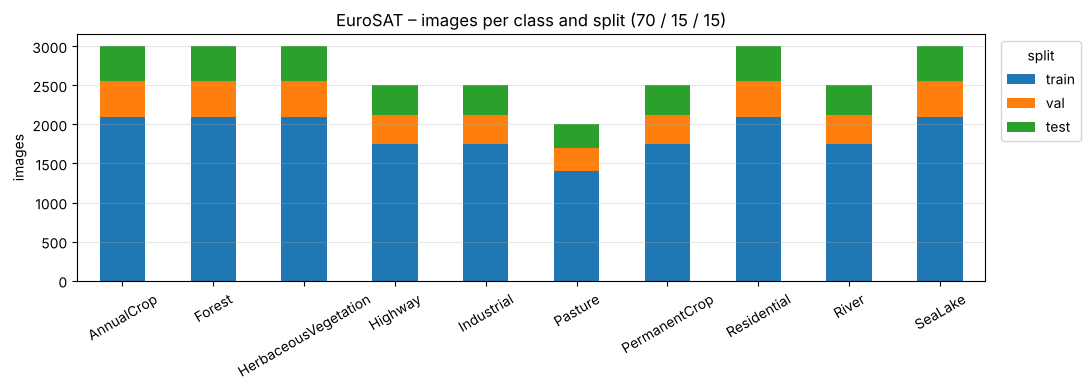

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
c = counts.drop(index="TOTAL")[["train", "val", "test"]].astype(int)
c.plot.bar(stacked=True, ax=ax, color=["#1f77b4", "#ff7f0e", "#2ca02c"])
ax.set_ylabel("images"); ax.set_xlabel(""); ax.set_title("EuroSAT – images per class and split (70 / 15 / 15)")
ax.legend(title="split", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.tick_params(axis="x", rotation=30); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eurosat_class_distribution.png", dpi=150); plt.show()

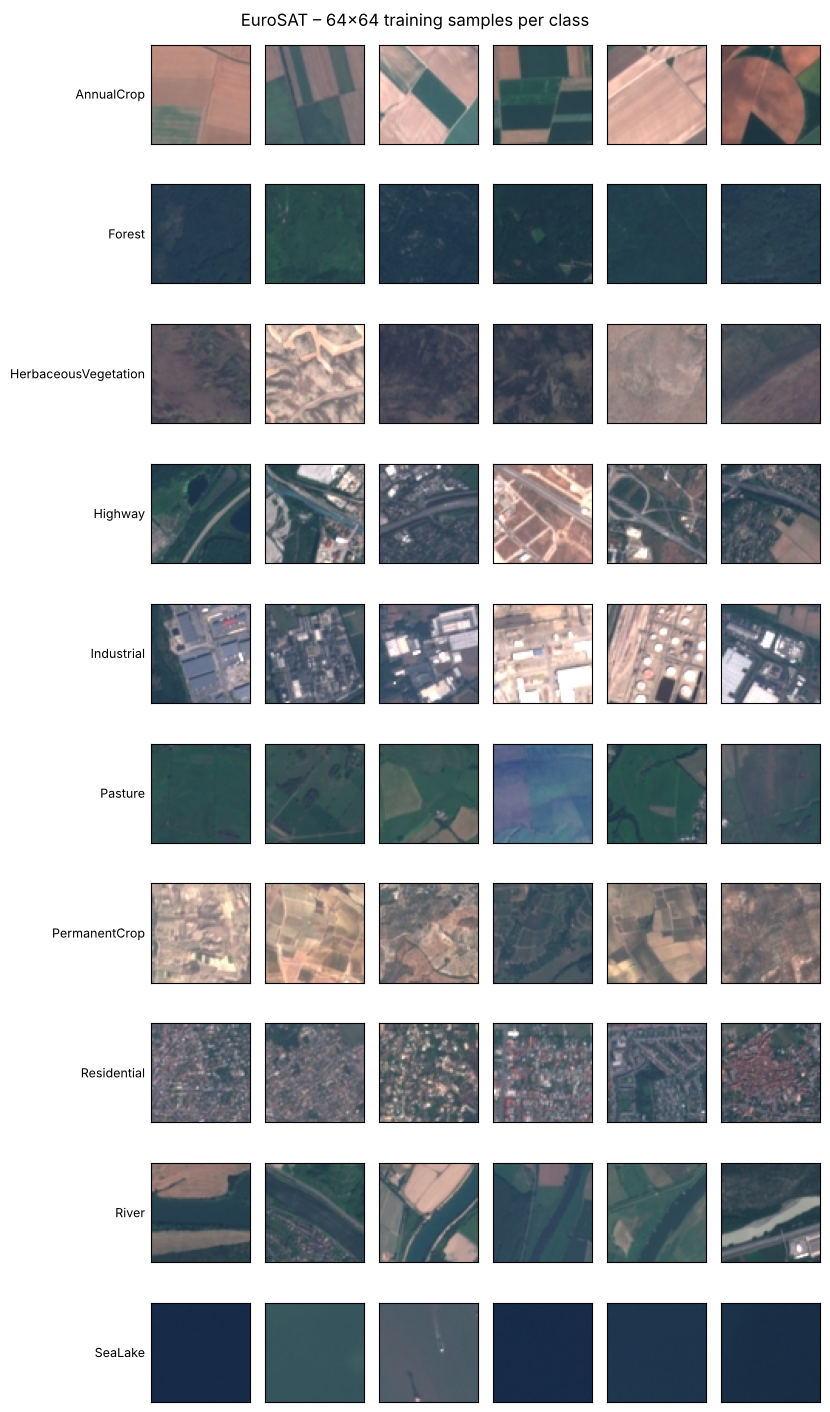

In [7]:
rng = np.random.default_rng(SEED)
n_show = 6
fig, ax = plt.subplots(len(CLASS_NAMES), n_show, figsize=(n_show * 1.4, len(CLASS_NAMES) * 1.45))
for i, cls in enumerate(CLASS_NAMES):
    picks = rng.choice(df[(df.label == cls) & (df.split == "train")].zip_path.values, n_show, replace=False)
    for j, p in enumerate(picks):
        ax[i, j].imshow(Image.open(io.BytesIO(zf.read(p)))); ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
    ax[i, 0].set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle("EuroSAT – 64×64 training samples per class")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eurosat_samples.png", dpi=150); plt.show()